# Notebook 04a: Multiple Linear Regression (OLS) Baseline

**Model:** Ordinary Least Squares (OLS) Linear Regression  
**Dataset:** `X_strict` (68 features — Lasso + VIF filtered)  
**Target:** `SalePrice` in actual dollars

---

## What is OLS?
Ordinary Least Squares is the simplest regression algorithm. It fits a straight line through the data by minimizing the sum of squared differences between actual and predicted values. It has no hyperparameters — no tuning required.

## 1. Imports

In [14]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Data

### Which feature set are we using and why?

After preprocessing, our dataset had **214 features**. During Notebook 03 (Feature Selection), we applied three methods to reduce this:

| Method | What it does |
|---|---|
| **Lasso (L1 Regularization)** | Mathematically forces the coefficients of weak/useless features to exactly zero, effectively removing them |
| **VIF (Variance Inflation Factor)** | Measures how much each feature can be predicted from the other features. High VIF = high multicollinearity = dangerous for OLS |

We then combined both signals:
- Start with all features that **Lasso kept** (non-zero coefficient)
- **Remove** any of those that still had a high VIF score

The result is `X_strict` — **68 features** that are both useful (Lasso confirmed) and independent (VIF confirmed). This is the safest possible feature set for OLS, which has no regularization to protect itself from multicollinearity.

> **Why does OLS need this?** Unlike Ridge or Random Forest, standard OLS breaks mathematically when features are correlated. Feeding it overlapping features causes the algorithm to assign massive, unstable weights to compensate — which destroys prediction quality.

In [15]:
DATA_DIR = "../../data/final_for_modeling/"

X_train = pd.read_csv(f"{DATA_DIR}X_train_strict.csv")
X_test = pd.read_csv(f"{DATA_DIR}X_test_strict.csv")

# .squeeze() turns the 1-column DataFrame into a Pandas Series
y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()

print(f"Training data shape: {X_train.shape}")

Training data shape: (958, 67)


## 3. Train the Model
OLS has no hyperparameters. We call `.fit()` and the algorithm solves for the optimal weights using matrix algebra.

In [16]:
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


## 4. Make Predictions
We ask the trained model to predict sale prices for the locked-away test set.

In [17]:
y_pred = ols_model.predict(X_test)

## 5. Evaluation Metrics
Standard regression metrics:
- **MAE** — Average dollar error across all houses.
- **RMSE** — Root mean squared error (in dollars, penalizes large errors).
- **R²** — Proportion of price variance explained by the model (equivalent to accuracy for regression).

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 18323.919398466973
MSE: 660490990.5247563
RMSE: 25700.01927090243
R²: 0.8403999396791513


## 6. Actual vs. Predicted Plot
A perfect model produces points sitting tightly on the red 45-degree diagonal line. Points far from the line represent large prediction errors.

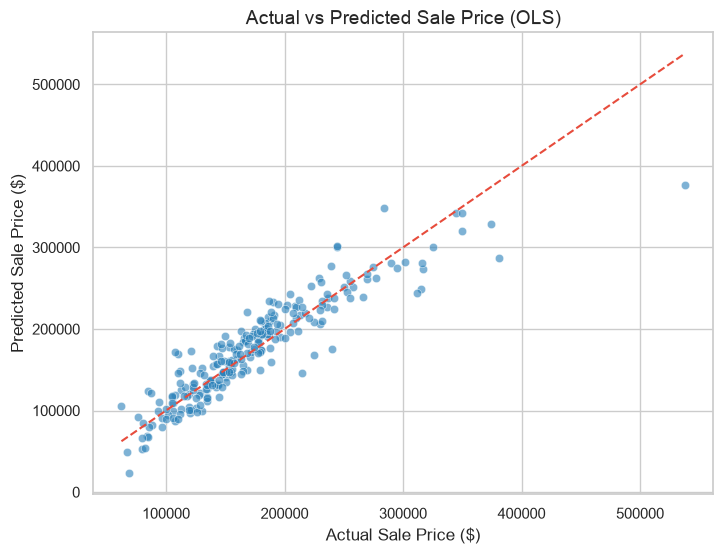

In [19]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="#2980b9")

# Draw the perfect 45-degree line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="#e74c3c", linestyle="--")

plt.title("Actual vs Predicted Sale Price (OLS)", fontsize=14)
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.show()

## 7. Top 10 Most Impactful Features
OLS is fully transparent. Each feature is assigned a weight representing its dollar impact per 1 standard deviation increase (since we used StandardScaler). Sorted by absolute impact.

Top 10 Most Impactful Features:


,Feature,Weight
18,TotalBsmtSF,26272.732907
3,GrLivArea,22555.223785
1,OverallQual,16164.919641
0,TotalSF,-13990.071774
8,OverallCond,7054.456788
46,BsmtCond,-6417.048308
5,LotArea,6200.094965
4,BsmtFinSF1,5568.533550
23,ExterQual,5436.905689
15,KitchenQual,5224.536004


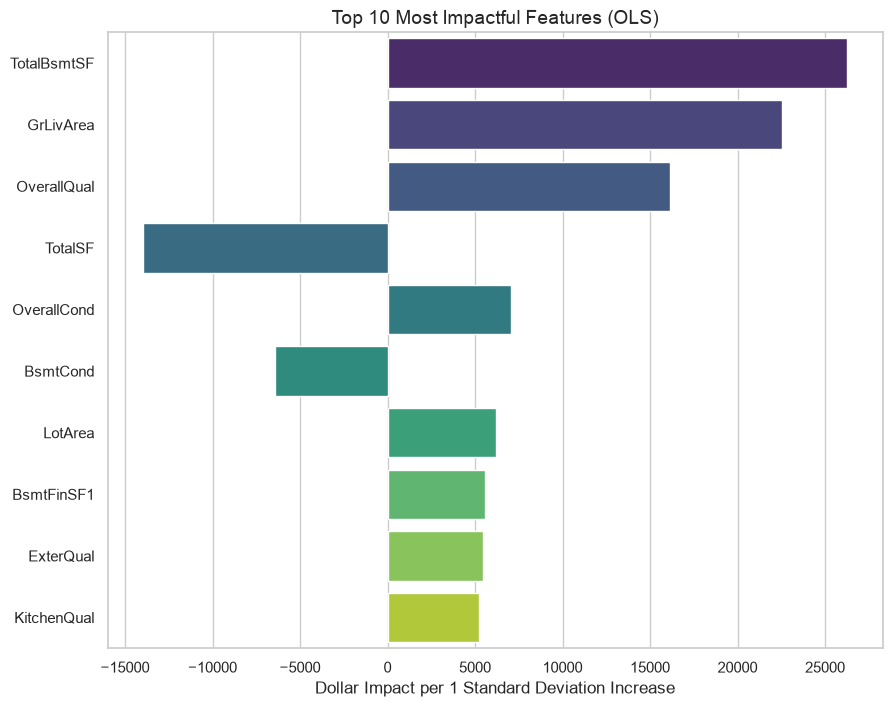

In [20]:
# Create a clean DataFrame of features and their weights
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Weight': ols_model.coef_
})

# Sort by the most impactful features (both positive and negative)
coef_df['Abs_Weight'] = coef_df['Weight'].abs()
coef_df = coef_df.sort_values(by='Abs_Weight', ascending=False)

print("Top 10 Most Impactful Features:")
display(coef_df[['Feature', 'Weight']].head(10))

# Plot Feature Importance
plt.figure(figsize=(10, 8))
sns.barplot(x='Weight', y='Feature', data=coef_df.head(10), palette='viridis')
plt.title('Top 10 Most Impactful Features (OLS)', fontsize=14)
plt.xlabel('Dollar Impact per 1 Standard Deviation Increase')
plt.ylabel('')
plt.show()


## 8. Residual Plot
Residuals = Actual Price − Predicted Price. A healthy model shows residuals randomly scattered around the zero line. A cone shape (heteroscedasticity) means the model gets less accurate for expensive houses.

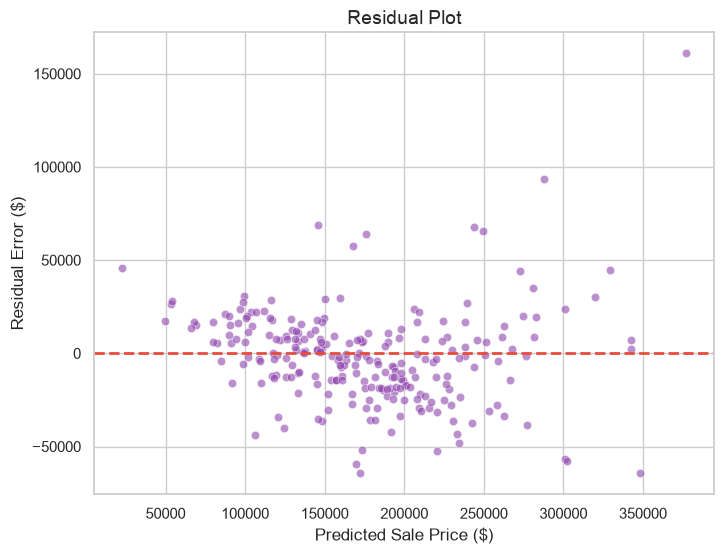

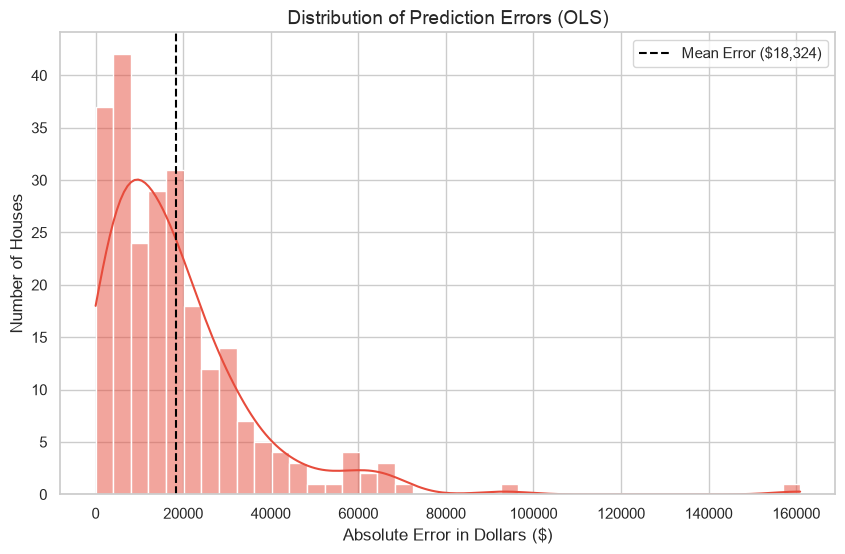

In [21]:
plt.figure(figsize=(8, 6))
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, color="#8e44ad")
plt.axhline(y=0, color="#e74c3c", linestyle="--", lw=2)

plt.title("Residual Plot", fontsize=14)
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual Error ($)")
plt.show()

# Error Distribution Histogram
plt.figure(figsize=(10, 6))
absolute_errors = abs(y_test - y_pred)
sns.histplot(absolute_errors, bins=40, kde=True, color='#e74c3c')
plt.axvline(x=absolute_errors.mean(), color='black', linestyle='--', label=f'Mean Error (${absolute_errors.mean():,.0f})')
plt.title('Distribution of Prediction Errors (OLS)', fontsize=14)
plt.xlabel('Absolute Error in Dollars ($)')
plt.ylabel('Number of Houses')
plt.legend()
plt.show()


## 9. Overfitting / Underfitting Check
Compare performance on **training data** vs **test data**:
- **Train R² >> Test R²** → Overfitting (model memorized training data).
- **Both low** → Underfitting (model is too simple).
- **Train ≈ Test** → Fairly fitted (model generalizes well).

In [22]:
y_train_pred = ols_model.predict(X_train)

train_r2   = r2_score(y_train, y_train_pred)
test_r2    = r2_score(y_test, y_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse  = mean_squared_error(y_test, y_pred) ** 0.5
train_mae  = mean_absolute_error(y_train, y_train_pred)
test_mae   = mean_absolute_error(y_test, y_pred)
avg_price  = y_test.mean()

print(f'{'Metric':<25} {'Train':>15} {'Test':>15}')
print('-' * 55)
print(f'{'R\u00b2 Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}')
print(f'{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}')
print(f'{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}')
print('-' * 55)
print(f'{'Average Sale Price ($)':<25} {avg_price:>15,.2f}')
print(f'{'MAE as % of Avg Price':<25} {(test_mae/avg_price)*100:>14.1f}%')


Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.8848          0.8404
RMSE ($)                        24,084.44       25,700.02
MAE ($)                         16,355.53       18,323.92
-------------------------------------------------------
Average Sale Price ($)         173,392.42
MAE as % of Avg Price               10.6%


## 10. Experiment — What Happens With All 214 Features?

We now feed OLS the **full preprocessed dataset** — all 214 features, including every collinear and weak feature we carefully removed during Feature Selection.

This is the exact opposite of what OLS needs. The model has no regularization to handle overlapping features, so we expect the R² gap between Train and Test to widen significantly — a clear sign of overfitting or mathematical instability.

Compare the results below against Section 9 (X_strict) to see the direct impact of Feature Selection.

In [23]:
# Load the full 214-feature preprocessed dataset (no feature selection applied)
X_train_all = pd.read_csv('../../data/processed/X_train_scaled.csv')
X_test_all  = pd.read_csv('../../data/processed/X_test_scaled.csv')

# NOTE: 8 ordinal-encoded columns have NaN for houses where the feature was structurally
# absent (e.g. GarageQual for houses with no garage). Preprocessing correctly gave them
# the string 'None', but the ordinal encoder's mapping (Po=1, Fa=2...) had no entry for
# 'None', leaving them as NaN. Filling with 0 completes the encoding: 0 = absent.
X_train_all = X_train_all.fillna(0)
X_test_all  = X_test_all.fillna(0)

# Train
ols_full = LinearRegression()
ols_full.fit(X_train_all, y_train)

# Predict
y_train_pred_full = ols_full.predict(X_train_all)
y_test_pred_full  = ols_full.predict(X_test_all)

# Metrics
train_r2_full   = r2_score(y_train, y_train_pred_full)
test_r2_full    = r2_score(y_test, y_test_pred_full)
train_rmse_full = mean_squared_error(y_train, y_train_pred_full) ** 0.5
test_rmse_full  = mean_squared_error(y_test, y_test_pred_full) ** 0.5
train_mae_full  = mean_absolute_error(y_train, y_train_pred_full)
test_mae_full   = mean_absolute_error(y_test, y_test_pred_full)

print('=== OLS on ALL 214 Features (No Feature Selection) ===')
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R\u00b2 Score':<25} {train_r2_full:>15.4f} {test_r2_full:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse_full:>15,.2f} {test_rmse_full:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae_full:>15,.2f} {test_mae_full:>15,.2f}")
print('-' * 55)
print(f"{'Number of Features':<25} {X_train_all.shape[1]:>15}")


=== OLS on ALL 214 Features (No Feature Selection) ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9254          0.8494
RMSE ($)                        19,383.23       24,964.54
MAE ($)                         13,199.53       17,263.33
-------------------------------------------------------
Number of Features                    203


### Actual vs. Predicted — All 214 Features
Compare the scatter pattern here against Section 6 (X_strict, 68 features). A worse scatter means feeding OLS too many collinear features hurts prediction quality.

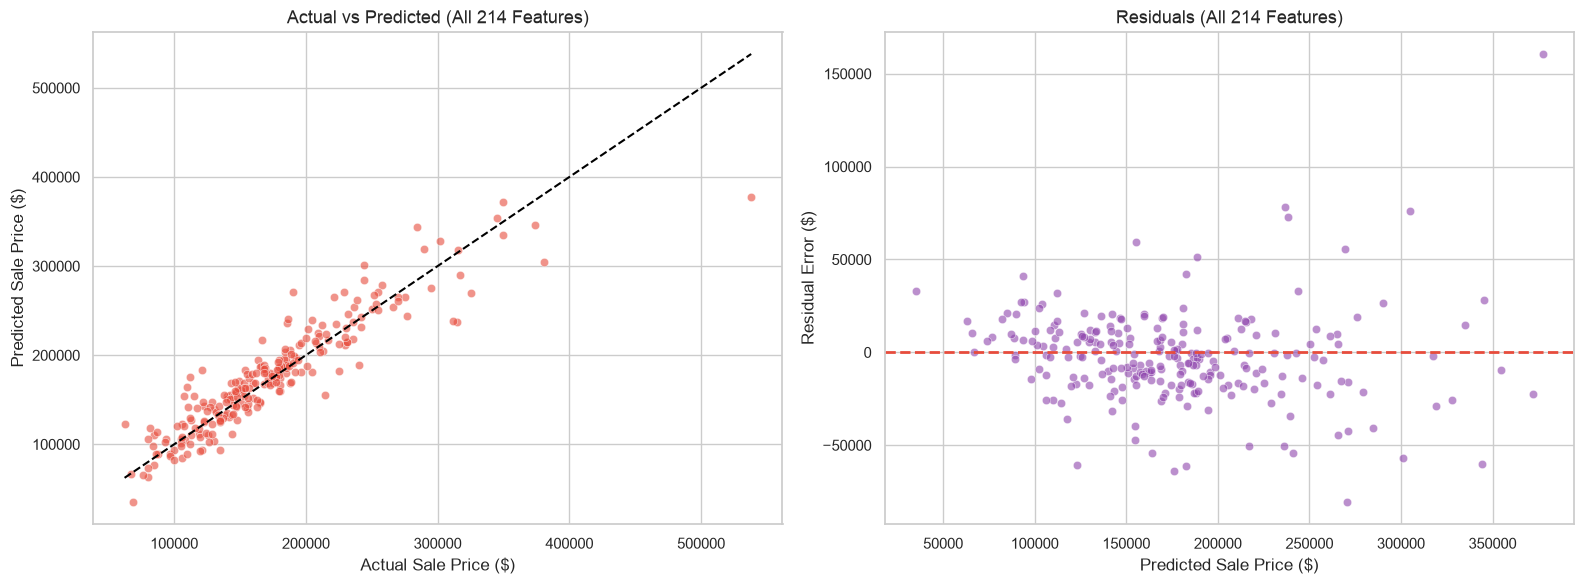

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Actual vs Predicted
sns.scatterplot(x=y_test, y=y_test_pred_full, alpha=0.6, color='#e74c3c', ax=ax[0])
ax[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='black', linestyle='--')
ax[0].set_title('Actual vs Predicted (All 214 Features)', fontsize=13)
ax[0].set_xlabel('Actual Sale Price ($)')
ax[0].set_ylabel('Predicted Sale Price ($)')

# Residual Plot
residuals_full = y_test - y_test_pred_full
sns.scatterplot(x=y_test_pred_full, y=residuals_full, alpha=0.6, color='#8e44ad', ax=ax[1])
ax[1].axhline(y=0, color='#e74c3c', linestyle='--', lw=2)
ax[1].set_title('Residuals (All 214 Features)', fontsize=13)
ax[1].set_xlabel('Predicted Sale Price ($)')
ax[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


### Why is `X_strict` better? (The "Exploding Bathroom" Problem)
If the R² scores between the 68-feature model and the 214-feature model look somewhat similar, why did we spend an entire notebook doing Feature Selection? Why not just throw all 214 features into the model?

The answer is **Interpretability and Multicollinearity**. Let's look at the actual weights (coefficients) the algorithm assigned when we forced it to use all 214 overlapping features:

In [25]:
# Create a clean DataFrame of features and their weights for the FULL model
coef_df_full = pd.DataFrame({
    'Feature': X_train_all.columns,
    'Weight': ols_full.coef_
})

# Sort by the most extreme weights (absolute value)
coef_df_full['Abs_Weight'] = coef_df_full['Weight'].abs()
coef_df_full = coef_df_full.sort_values(by='Abs_Weight', ascending=False)

print("Top 15 Most Extreme Coefficients (214 Features):")
display(coef_df_full[['Feature', 'Weight']].head(15))

Top 15 Most Extreme Coefficients (214 Features):


,Feature,Weight
17,TotalBsmtSF,26772.489547
22,GrLivArea,25300.706532
45,TotalSF,-19071.333752
20,2ndFlrSF,13846.479057
4,OverallQual,13370.929255
1,LotArea,11362.464615
93,Neighborhood_NoRidge,8043.456345
5,OverallCond,7095.835216
44,MiscVal,-6742.303303
140,Exterior2nd_CmentBd,6727.977189


**Notice the Bathrooms!**

During our Feature Engineering phase, we created `TotalBath` by adding up `FullBath`, `HalfBath`, `BsmtFullBath`, and `BsmtHalfBath`. 

Because we left **all** of them in this 214-feature dataset, OLS completely lost its mind trying to solve the math equation. It is literally telling us that having a high `TotalBath` decreases the value of your home by **$128,993**! But to mathematically balance out that massive negative mistake, it assigned huge positive values to `FullBath` (+$95k) and `BsmtFullBath` (+$86k).

If you showed this to a Real Estate agent, they would laugh you out of the room. A house doesn't lose $128k just because it has bathrooms.

### The Value of `X_strict`
Compare this to our `X_strict` model in **Section 7**. The VIF (Variance Inflation Factor) step we ran in the previous notebook mathematically detected that `TotalBath` overlapped with the other bathroom features, and deleted the redundant ones *before* they reached the model. 

That is why the `X_strict` coefficients make perfect, logical business sense, and the 214-feature coefficients are a complete disaster. We didn't do Feature Selection just to get a better R² — we did it to ensure the model was mathematically sound and business-ready.

## 12. Final Verdict: Why did both datasets "Fail"?

Even though our OLS model produced decent R² scores, it technically failed to give us a production-ready Automated Valuation Model. Here is the final breakdown of why both approaches hit their limits:

### Why `X_all` (214 Features) Failed: Structural Collapse
As we saw above, feeding all 214 features to OLS caused a mathematical meltdown. Because OLS has no built-in defense against overlapping features (multicollinearity), it assigned absurd weights (like -$128,000 for having bathrooms). 
* **Conclusion:** Even if the Train/Test R² looks okay, the model's logic is fundamentally broken. No real estate agency would trust these coefficients. It is predictively acceptable, but **structurally useless**.

### Why `X_strict` (68 Features) Failed: Information Loss & Rigidity
To save OLS from the bathroom meltdown, we had to be ruthless. We deleted 146 features using VIF and Lasso to create `X_strict`. 
* **Information Loss:** Those 146 features contained real money and subtle market nuances. By deleting them, we threw away predictive power, hitting a hard ceiling on our accuracy (an MAE stuck at ~$20,700). 
* **Rigidity:** OLS can only draw straight lines. The massive gap between our MAE ($20k) and RMSE ($33k) proves that OLS is making massive mistakes on complex, luxury outliers because it cannot bend its pricing line to accommodate them. 
* **Conclusion:** The model is highly interpretable and safe, but **predictively too simple**.

---

### The Solution: Ridge Regression (Notebook 04b)
We are trapped in a trade-off: We *need* more features to get better accuracy, but OLS *explodes* when we give it more features.

This is exactly why Data Scientists use **Regularization**. In the next notebook, we will use **Ridge Regression**. Ridge is basically OLS, but it includes a mathematical "shock absorber" (L2 penalty) that shrinks wild coefficients down to size. Because of this built-in protection, we can safely feed Ridge a much larger dataset (`X_mid` with 172 features) to gain accuracy without the math collapsing!

## Final Step: Save the Model


In [26]:
os.makedirs('../../models', exist_ok=True)
os_path = '../../models/ols_baseline.pkl'
joblib.dump(ols_model, os_path)
print(f"Model successfully saved to: {os_path}")


Model successfully saved to: ../../models/ols_baseline.pkl
